# Explore el costo y los límites del suavizado de ancho

**Pregunta:** ¿Cómo afectan el ancho objetivo y el plan elegido a los tramos reducidos, los movimientos impedidos por capacidad y el cambio firmado de VPN?

**Nivel:** 2 · Fundamentos

**Prerrequisitos:** Complete el tema 01, planificación CPIT y cotas.

**Tiempo de lectura:** 28 minutos

## Objetivos

Este notebook estudia compensaciones y no presenta el suavizado como limpieza sin costo. En un caso sintético fijo aplica tres anchos objetivo al mismo plan factible y compara otro plan bajo el mismo objetivo. Para cada resultado, el informe distingue bloques estrechos detectados, bloques movidos, movimientos impedidos por capacidad y cambio de VPN. Los controles verifican el plan devuelto. El experimento muestra por qué un ancho mínimo que no cambia no significa que el método no hizo nada: los tramos aislados pueden no tener vecinos elegibles y la capacidad puede impedir movimientos. También explicita el límite: el suavizado no recupera capacidad perdida por un período receptor restringido y el proxy por bloques no demuestra acceso físico, estabilidad de taludes ni geometría de equipos.

## Preparación

Desde la raíz del repositorio, instale el entorno fijado con `pip install oreblocks==0.6.5 numpy==2.5.1 scipy==1.18.1 matplotlib==3.11.2`. `oreblocks==0.6.5`.

```bash
pip install oreblocks==0.6.5 numpy==2.5.1 scipy==1.18.1 matplotlib==3.11.2
```

In [1]:
# Cargue la canalización de instancias y los métodos geométricos de OreBlocks.
import importlib.metadata as metadata
import sys
from pathlib import Path
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path('../../../data-pipeline').resolve()))
from pipeline.io.schema import Case, DepositSpec, Scenario
from pipeline.model.instances import build_instance
import oreblocks as ob
print('oreblocks', metadata.version('oreblocks'))

oreblocks 0.6.5


## Datos

La entrada declarada la genera la canalización MIT de PhaseFlow: gemelo sintético porfídico, dimensiones 8×8×4, semilla fija 41, seis períodos y dos límites de recursos. La canalización entrega coordenadas, precedencias, ley y tonelaje. OreBlocks 0.6.5 calcula el plan, las métricas de coherencia y el suavizado. No se usa un modelo de bloques MineLib publicado. El ancho objetivo está en bloques de grilla porque este caso no declara dimensiones topográficas; no lo convierta a metros sin tamaño de celda declarado. Bai et al. discuten unos 100 m como objetivo en otro modelo de diseño de pushbacks. Ese número es contexto y no el objetivo de este plan sintético.

## Método



### Paso 1: construya el caso



In [2]:
# Genere con PhaseFlow un caso sintético con semilla.
case = Case(
    id='operability-porphyry-8x8x4', category='teaching',
    title_en='Porphyry coherence lesson', title_es='Leccion de coherencia porfídica',
    deposit=DepositSpec(kind='twin', archetype='porphyry', dims=(8, 8, 4), seed=41),
    scenario=Scenario(periods=6, discount_rate=0.08,
        capacity_fraction=(0.85, 0.55), resource_names=('mining', 'processing')),
)
instance = build_instance(case)
print('contrato aceptado:', instance.report.ok, '| bloques:', instance.n_blocks)

contrato aceptado: True | bloques: 256


### Paso 1: compare planes iniciales

El plan inicial afecta qué períodos vecinos pueden recibir un bloque estrecho. Comparamos dos planes generados por métodos en la misma entrada; ninguno se elige a partir del resultado de ancho.

In [3]:
# Genere el plan Expected factible como referencia compartida.
expected, _ = ob.solve_cpit(
    instance.cpit, instance.precedence,
    method='expected', local_search=False,
)
print(expected.method, round(expected.npv, 2))

toposort:expected[r1] 6241283.54


Genere un segundo plan con prioridad voraz. Su valor y geometría pueden cambiar porque el orden de extracción es distinto.

In [4]:
# Genere otro plan factible con la prioridad voraz.
greedy, _ = ob.solve_cpit(
    instance.cpit, instance.precedence,
    method='greedy', local_search=False,
)
print(greedy.method, round(greedy.npv, 2))

toposort:greedy 3314787.03


### Paso 2: varíe el ancho objetivo



In [5]:
# Aplique tres anchos objetivo al mismo plan factible.
reports = []
for width in (2, 3, 4):
    result, summary = ob.enforce_min_width(
        instance.cpit, expected, instance.x, instance.y,
        instance.level, instance.precedence, target_width=width,
    )
    reports.append((width, result, summary))
print([(width, summary.moved_blocks, summary.blocked_by_capacity) for width, _, summary in reports])

[(2, 25, 29), (3, 25, 29), (4, 25, 32)]


Ejecute los controles del paquete en cada resultado suavizado. Un control aprobado respalda factibilidad modelada de capacidad y precedencias; no valida accesos ni condiciones geotécnicas.

In [6]:
# Verifique cada resultado con controles independientes del paquete.
for width, result, summary in reports:
    controls = ob.run_controls(instance.cpit, instance.precedence, result)
    print(width, '| controles:', controls.__dict__, '| cambio VPN %:', round(-summary.npv_cost_pct, 4))

2 | controles: {'duality_set_matches': True, 'duality_bound_error': 0.0, 'bound_geq_feasible': True, 'order_invariant': True, 'order_invariance_error': 0.0} | cambio VPN %: 0.0706
3 | controles: {'duality_set_matches': True, 'duality_bound_error': 0.0, 'bound_geq_feasible': True, 'order_invariant': True, 'order_invariance_error': 0.0} | cambio VPN %: 0.0706
4 | controles: {'duality_set_matches': True, 'duality_bound_error': 0.0, 'bound_geq_feasible': True, 'order_invariant': True, 'order_invariance_error': 0.0} | cambio VPN %: 0.0706


Grafique la reducción de bloques estrechos frente al costo VPN para cada objetivo. Así se ve la compensación sin reducirla a una sola puntuación.

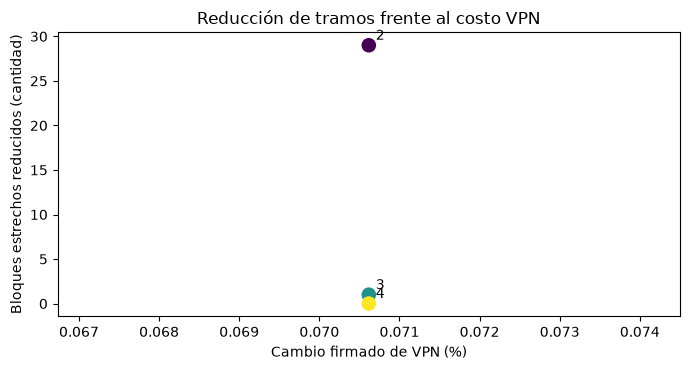

In [7]:
# Grafique reducción de tramos y cambio firmado de VPN por objetivo.
widths = [row[0] for row in reports]
reductions = [row[2].below_target_before - row[2].below_target_after for row in reports]
changes = [-row[2].npv_cost_pct for row in reports]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.scatter(changes, reductions, c=widths, cmap='viridis', s=90)
for target_cost, reduction, width in zip(changes, reductions, widths):
    ax.annotate(str(width), (target_cost, reduction), xytext=(5, 4), textcoords='offset points')
ax.set(
    title='Reducción de tramos frente al costo VPN',
    xlabel='Cambio firmado de VPN (%)', ylabel='Bloques estrechos reducidos (cantidad)',
)
fig.tight_layout()
plt.show()

### Figura 1

Cada punto es un ancho objetivo aplicado al mismo plan. Las etiquetas indican el objetivo en bloques. Un punto más alto representa mayor reducción de bloques estrechos; uno más a la derecha, mayor cambio firmado de VPN (ganancia o menor pérdida). Es una compensación medida, no un óptimo universal. Ningún punto demuestra acceso físico ni estabilidad.

Compare ahora los rechazos por capacidad en las tres ejecuciones. Un movimiento puede ser geométricamente atractivo y quedar bloqueado porque algún recurso receptor no tiene capacidad.

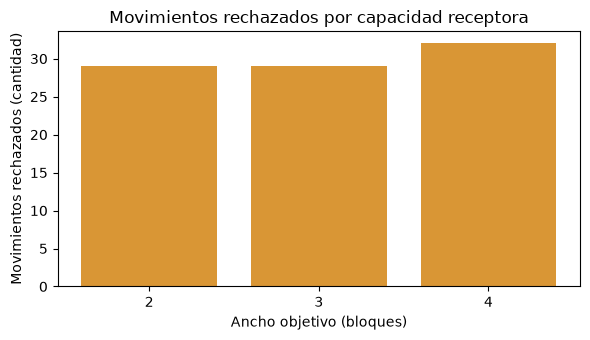

In [8]:
# Grafique los movimientos rechazados por capacidad para cada objetivo.
blocked = [row[2].blocked_by_capacity for row in reports]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar([str(width) for width in widths], blocked, color='#d99635')
ax.set(
    title='Movimientos rechazados por capacidad receptora',
    xlabel='Ancho objetivo (bloques)', ylabel='Movimientos rechazados (cantidad)',
)
fig.tight_layout()
plt.show()

### Figura 2

Las barras cuentan movimientos rechazados porque al período receptor le faltaba espacio en al menos un recurso. Explican por qué aumentar el objetivo no garantiza una mejora equivalente del ancho. Cero rechazos no demuestra que se eliminaron todos los tramos: bloques aislados pueden no tener vecinos mayoritarios y las precedencias pueden impedir movimientos. El VPN y la factibilidad siguen siendo necesarios.

Los objetivos de ancho pueden reducir tramos estrechos y cambiar la conectividad; mide cada mapa por período para interpretar la compensación.

In [9]:
# Measure connected runs for each returned width alternative.
coherence_by_width = {
    width: ob.schedule_coherence(
        result.period_of_block, instance.x, instance.y,
        instance.level, instance.cpit.n_periods,
    )
    for width, result, summary in reports
}
print({width: [(row.components, row.min_width_blocks) for row in rows]
       for width, rows in coherence_by_width.items()})


{2: [(1, 1), (4, 1), (4, 1), (3, 1), (6, 1), (3, 1)], 3: [(1, 1), (4, 1), (4, 1), (3, 1), (6, 1), (3, 1)], 4: [(1, 1), (4, 1), (4, 1), (3, 1), (6, 1), (3, 1)]}


El objetivo de ancho es una preferencia de postproceso aplicada a un plan temporal que ya era factible. Intenta mover corridas extraídas estrechas a períodos vecinos y conservar precedencia y límites de recursos. Por eso los movimientos rechazados del informe son significativos: muestran dónde el suavizado geométrico choca con la capacidad disponible del período receptor. Muchos rechazos no implican que el solver falló; pueden indicar que la geometría solicitada no cabe en la holgura existente.

Interpreta juntas las tres salidas. La cantidad de bloques bajo el objetivo mide la meta geométrica, los componentes conectados describen fragmentación a escala del mapa por período y el cambio firmado de VPN mide el costo económico bajo los supuestos de descuento y valor del modelo. Ninguna métrica reemplaza a las otras. Un objetivo puede reducir corridas estrechas sin cambiar la cantidad de componentes, o mejorar continuidad con un costo de valor medible. La heurística de ancho es local y sus informes dependen del plan inicial; no demuestra que produzca el mejor plan operable global.

No se garantiza que elevar el objetivo de dos a tres y cuatro mejore monótonamente cada métrica. Cada objetivo cambia los movimientos propuestos y las restricciones de capacidad activas; una solicitud mayor puede encontrar más rechazos o elegir una secuencia distinta de movimientos aceptados. El cambio de VPN tampoco es un costo minero realizado: omite equipos, accesos, geotecnia y costos de secuencia que no están codificados en esta instancia. Para un estudio real, barre los objetivos sobre la misma base, inspecciona mapas por período y razones de rechazo, y evalúa las alternativas operacionalmente plausibles con los criterios detallados de diseño de la mina.


## Resultados

**Respuesta:** Con ancho objetivo 3, el informe mueve 25 bloques, rechaza 29 por capacidad y reduce los bloques estrechos de 90 a 89. El cambio firmado de VPN es +0.0706 % (una ganancia, no un costo). Los controles verifican factibilidad CPIT modelada, no operabilidad física.

In [10]:
# Informe los valores del objetivo tres usados en la respuesta.
selected = next(summary for width, result, summary in reports if width == 3)
print(f'movidos={selected.moved_blocks}; rechazados={selected.blocked_by_capacity}')
print(f'bloques_estrechos={selected.below_target_before}->{selected.below_target_after}')
print(f'cambio_vpn_pct={-selected.npv_cost_pct:.4f}')

movidos=25; rechazados=29
bloques_estrechos=90->89
cambio_vpn_pct=0.0706


## Resumen

Comparó anchos objetivo y otro plan inicial con entradas idénticas. La compensación depende del caso: el ancho deseado cambia la geometría, pero capacidad y precedencias deciden qué movimientos ocurren. El postproceso no puede hacer factible un plan inviable, certificar un diseño geotécnico ni garantizar un ancho físico mínimo. Para un caso real, convierta grilla a metros, modele caminos y accesos por fase, verifique todos los recursos y pida revisión a especialistas de planificación minera.

## Referencias

- OreBlocks 0.6.5: `oreblocks.schedule_coherence`, `oreblocks.enforce_min_width`.
- Chicoisne et al. (2012), multi-period open-pit planning: https://doi.org/10.1287/opre.1120.1050.
- Bai et al. (2018), minimum mining width and pushback design: https://doi.org/10.17159/2411-9717/2018/v118n5a8.
- PhaseFlow method evidence: `docs/methodologies/10_operability.md`.